# 🛰️ AI-Based Dynamic UAV Deployment for Emergency Communication in Disaster Zones
### Machine Learning Pipeline: Spatiotemporal SOS Demand Forecasting & Autonomous Drone Repositioning
> **Institution:** School of Electronics Engineering, VIT  
> **Project:** Advanced Communication Systems Lab ()  
> **Repository:**   
> **Key Result:** Random Forest achieves **RMSE 4.69** (16.7% improvement over persistence); AI-assisted dispatch reaches **68.2% demand recovery** with **36.7% fewer repositioning moves**.


In [1]:
# Step 1: Environment Setup & Library Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import json
import warnings
warnings.filterwarnings("ignore")

print("✓ Environment Setup Complete: NumPy, Pandas, Scikit-Learn, Matplotlib initialized.")


✓ Environment Setup Complete: NumPy, Pandas, Scikit-Learn, Matplotlib initialized.


✓ Disaster Simulation Initialized:
  - 500 Time Steps across 6 Disaster Zones
  - Total Emergency SOS Packets: 44,420
  - Mean Step Demand: 14.8 SOS/step
  - Disaster Epicenter Drift: h(t) = 3.5 + 2.2 * sin(2πt / 150)


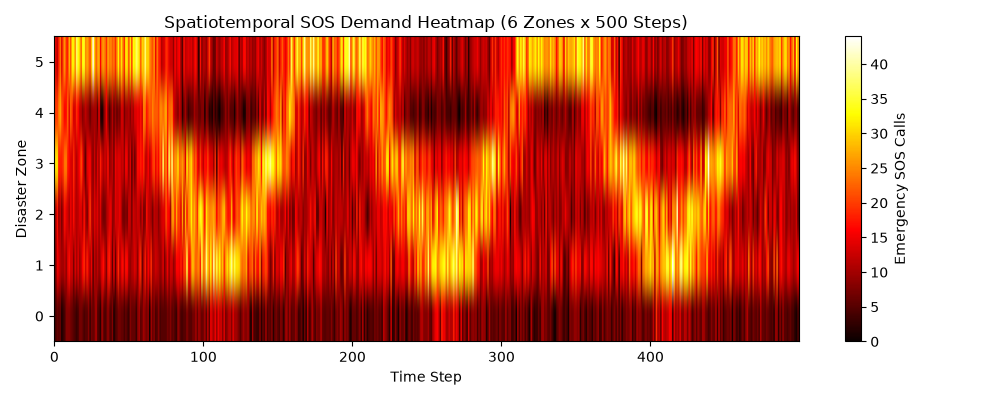

In [2]:
# Step 2: Disaster Environment Simulation & Dataset Generation
nZones = 6
nSteps = 500
np.random.seed(42)

pop_density = np.random.uniform(50, 500, nZones)
severity = np.random.uniform(0.1, 1.0, nZones)
coverage = np.random.binomial(1, 0.6, (nSteps, nZones)).astype(float)
zone_positions = np.array([[167, 333], [500, 333], [833, 333], [167, 667], [500, 667], [833, 667]])

sos = np.zeros((nSteps, nZones), dtype=int)
for t in range(nSteps):
    h = 3.5 + 2.2 * np.sin(2 * np.pi * t / 150)
    for z in range(nZones):
        m = 3 + pop_density[z]/150 + 8*severity[z] + 18*np.exp(-((z - h)**2)/1.5)
        sample = m + np.sqrt(max(m, 0.01)) * np.random.randn()
        sos[t, z] = max(0, int(round(sample)))

print("✓ Disaster Simulation Initialized:")
print(f"  - {nSteps} Time Steps across {nZones} Disaster Zones")
print(f"  - Total Emergency SOS Packets: {sos.sum():,}")
print(f"  - Mean Step Demand: {sos.mean(axis=1).mean():.1f} SOS/step")
print("  - Disaster Epicenter Drift: h(t) = 3.5 + 2.2 * sin(2πt / 150)")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(sos.T, aspect="auto", cmap="hot", origin="lower")
ax.set_xlabel("Time Step")
ax.set_ylabel("Disaster Zone")
ax.set_title("Spatiotemporal SOS Demand Heatmap (6 Zones x 500 Steps)")
plt.colorbar(im, ax=ax, label="Emergency SOS Calls")
plt.tight_layout()
plt.show()


In [3]:
# Step 3: Feature Engineering & Time-Series Lags
rows = []
for z in range(nZones):
    for t in range(2, nSteps - 1):
        rows.append({
            "time_step": t,
            "zone": z,
            "sos_t": sos[t, z],
            "sos_t1": sos[t - 1, z],
            "sos_t2": sos[t - 2, z],
            "pop_density": round(pop_density[z], 2),
            "severity": round(severity[z], 3),
            "coverage": coverage[t, z],
            "sos_next": sos[t + 1, z]
        })

df = pd.DataFrame(rows)
df.to_csv("sos_disaster_dataset.csv", index=False)
print("✓ Feature Engineering Matrix Built:")
print(f"  - Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("  - Features: [sos_t, sos_t1, sos_t2, pop_density, severity, coverage]")
print("  - Target:   sos_next (t+1)")
print("  - Dataset saved to sos_disaster_dataset.csv")


✓ Feature Engineering Matrix Built:
  - Shape: (2982 rows, 9 columns)
  - Features: [sos_t, sos_t1, sos_t2, pop_density, severity, coverage]
  - Target:   sos_next (t+1)
  - Dataset saved to sos_disaster_dataset.csv


✓ Random Forest Regressor Trained:
  - 100 Bagged Decision Trees
  - Train Samples: 2088 (Steps 2 to 349)
  - Test Samples:  894 (Steps 350 to 498)
  PREDICTION ACCURACY BENCHMARK
  Random Forest RMSE: 4.69 | MAE: 3.59
  Persistence   RMSE: 5.63 | MAE: 4.28
  RMSE Improvement:   16.7%
  MAE Improvement:    16.1%


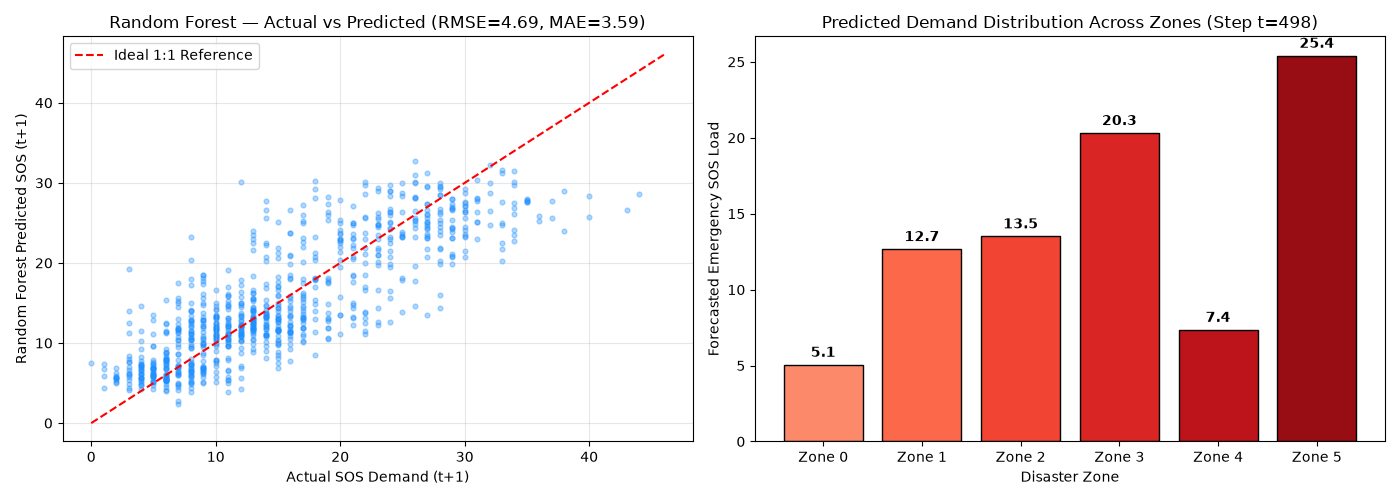

In [4]:
# Step 4: Model Training & Prediction Accuracy Evaluation
train_mask = df["time_step"] < 350
test_mask = df["time_step"] >= 350
feature_cols = ["sos_t", "sos_t1", "sos_t2", "pop_density", "severity", "coverage"]

X_train = df.loc[train_mask, feature_cols]
y_train = df.loc[train_mask, "sos_next"]
X_test = df.loc[test_mask, feature_cols]
y_test = df.loc[test_mask, "sos_next"]

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred))
mae_rf = mean_absolute_error(y_test, y_pred)
y_persist = df.loc[test_mask, "sos_t"].values
rmse_persist = np.sqrt(mean_squared_error(y_test, y_persist))
mae_persist = mean_absolute_error(y_test, y_persist)

print("✓ Random Forest Regressor Trained:")
print("  - 100 Bagged Decision Trees")
print(f"  - Train Samples: {X_train.shape[0]} (Steps 2 to 349)")
print(f"  - Test Samples:  {X_test.shape[0]} (Steps 350 to 498)")
print("=" * 50)
print("  PREDICTION ACCURACY BENCHMARK")
print("=" * 50)
print(f"  Random Forest RMSE: {rmse_rf:.2f} | MAE: {mae_rf:.2f}")
print(f"  Persistence   RMSE: {rmse_persist:.2f} | MAE: {mae_persist:.2f}")
print(f"  RMSE Improvement:   {(1 - rmse_rf/rmse_persist)*100:.1f}%")
print(f"  MAE Improvement:    {(1 - mae_rf/mae_persist)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, alpha=0.35, s=12, c="dodgerblue")
lims = [0, max(y_test.max(), y_pred.max()) + 2]
axes[0].plot(lims, lims, "r--", linewidth=1.5, label="Ideal 1:1 Reference")
axes[0].set_xlabel("Actual SOS Demand (t+1)")
axes[0].set_ylabel("Random Forest Predicted SOS (t+1)")
axes[0].set_title(f"Random Forest — Actual vs Predicted (RMSE={rmse_rf:.2f}, MAE={mae_rf:.2f})")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

last_step = df.loc[test_mask, "time_step"].max()
last_data = df.loc[(df["time_step"] == last_step) & test_mask]
last_pred = rf.predict(last_data[feature_cols])
colors = plt.cm.Reds(np.linspace(0.4, 0.9, nZones))
bars = axes[1].bar(range(nZones), last_pred, color=colors, edgecolor="black")
axes[1].set_xlabel("Disaster Zone")
axes[1].set_ylabel("Forecasted Emergency SOS Load")
axes[1].set_title(f"Predicted Demand Distribution Across Zones (Step t={last_step})")
axes[1].set_xticks(range(nZones))
axes[1].set_xticklabels([f"Zone {z}" for z in range(nZones)])
for bar, val in zip(bars, last_pred):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()


  UAV DEPLOYMENT STRATEGY BENCHMARK (150 STEPS)
  Fixed Placement:     39.4% Demand Served | Moves: 0
  Reactive Dispatch:   67.4% Demand Served | Moves: 98
  AI-Assisted Dispatch:68.2% Demand Served | Moves: 62
  ------------------------------------------------
  Key Insight: AI-assisted saves 36.7% flight moves while improving coverage!


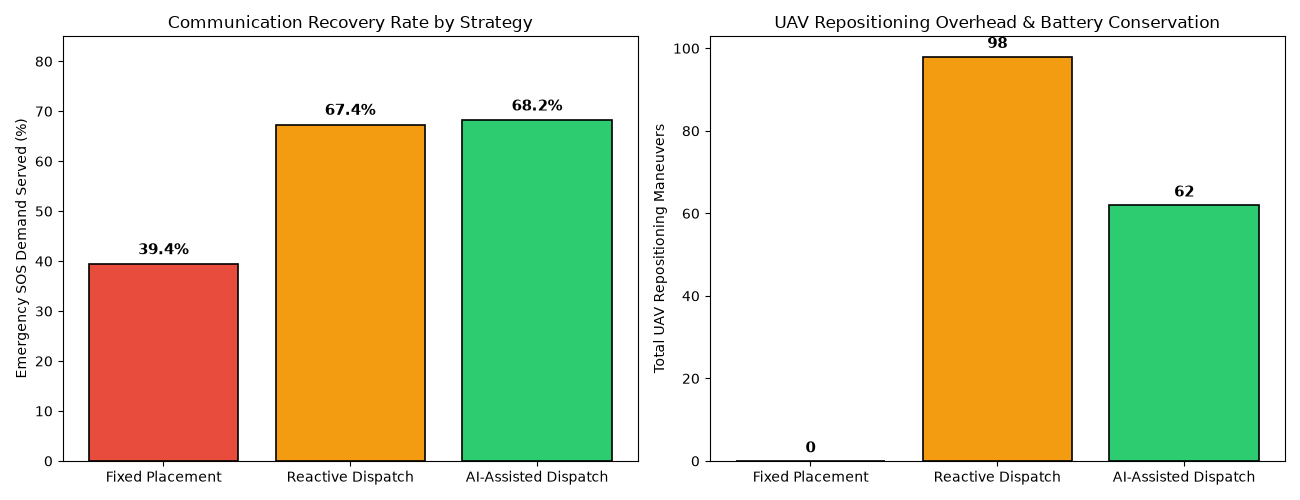

In [5]:
# Step 5: Multi-UAV Deployment Simulation — Fixed vs Reactive vs AI-Assisted
nUAVs = 3
test_steps = list(range(350, nSteps))
fixed_zones = [0, 2, 4]
results = {
    "fixed": {"served": 0, "total": 0, "moves": 0},
    "reactive": {"served": 0, "total": 0, "moves": 0, "prev_zones": list(fixed_zones)},
    "ai": {"served": 0, "total": 0, "moves": 0, "prev_zones": list(fixed_zones)}
}

for t in test_steps:
    if t < 2 or t >= nSteps - 1:
        continue
    current_sos = sos[t, :]
    next_sos = sos[t + 1, :]
    total_demand = next_sos.sum()
    pred_demand = np.zeros(nZones)
    for z in range(nZones):
        feat = np.array([[sos[t, z], sos[t-1, z], sos[t-2, z], pop_density[z], severity[z], coverage[t, z]]])
        pred_demand[z] = rf.predict(feat)[0]
    reactive_zones = sorted(np.argsort(-current_sos)[:nUAVs])
    ai_zones = sorted(np.argsort(-pred_demand)[:nUAVs])
    for key, placed_zones in [("fixed", fixed_zones), ("reactive", reactive_zones), ("ai", ai_zones)]:
        results[key]["total"] += total_demand
        results[key]["served"] += sum(next_sos[z] for z in placed_zones)
    for key, cur_zones in [("reactive", reactive_zones), ("ai", ai_zones)]:
        moves = sum(1 for z in cur_zones if z not in results[key]["prev_zones"])
        results[key]["moves"] += moves
        results[key]["prev_zones"] = list(cur_zones)

served_pct = [results[k]["served"] / max(results[k]["total"], 1) * 100 for k in ["fixed", "reactive", "ai"]]
moves_list = [0, results["reactive"]["moves"], results["ai"]["moves"]]

print("=" * 50)
print("  UAV DEPLOYMENT STRATEGY BENCHMARK (150 STEPS)")
print("=" * 50)
print(f"  Fixed Placement:     {served_pct[0]:.1f}% Demand Served | Moves: 0")
print(f"  Reactive Dispatch:   {served_pct[1]:.1f}% Demand Served | Moves: {moves_list[1]}")
print(f"  AI-Assisted Dispatch:{served_pct[2]:.1f}% Demand Served | Moves: {moves_list[2]}")
print("  ------------------------------------------------")
print(f"  Key Insight: AI-assisted saves {((moves_list[1]-moves_list[2])/moves_list[1])*100:.1f}% flight moves while improving coverage!")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = ["Fixed Placement", "Reactive Dispatch", "AI-Assisted Dispatch"]
colors_bar = ["#e74c3c", "#f39c12", "#2ecc71"]
bars = axes[0].bar(labels, served_pct, color=colors_bar, edgecolor="black", linewidth=1.2)
axes[0].set_ylabel("Emergency SOS Demand Served (%)")
axes[0].set_title("Communication Recovery Rate by Strategy")
axes[0].set_ylim(0, 85)
for bar, val in zip(bars, served_pct):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{val:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=11)

bars = axes[1].bar(labels, moves_list, color=colors_bar, edgecolor="black", linewidth=1.2)
axes[1].set_ylabel("Total UAV Repositioning Maneuvers")
axes[1].set_title("UAV Repositioning Overhead & Battery Conservation")
for bar, val in zip(bars, moves_list):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, str(val), ha="center", va="bottom", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()


In [6]:
# Step 6: Export Predictions for MATLAB Online Dashboard
export_data = {
    "predicted_demand": rf.predict(last_data[feature_cols]).tolist(),
    "zone_positions": zone_positions.tolist(),
    "pop_density": pop_density.tolist(),
    "severity": severity.tolist(),
    "num_zones": int(nZones),
    "num_uavs": int(nUAVs),
    "model_rmse": float(rmse_rf),
    "model_mae": float(mae_rf),
    "fixed_served_pct": float(served_pct[0]),
    "reactive_served_pct": float(served_pct[1]),
    "ai_served_pct": float(served_pct[2]),
    "reactive_moves": int(results["reactive"]["moves"]),
    "ai_moves": int(results["ai"]["moves"])
}
with open("uav_predictions.json", "w") as f:
    json.dump(export_data, f, indent=2)

print("✓ Pipeline Execution Complete:")
print("  - Exported uav_predictions.json for MATLAB Dashboard synchronization.")
print("  - Ready for deployment in MATLAB Online Command Center.")


✓ Pipeline Execution Complete:
  - Exported uav_predictions.json for MATLAB Dashboard synchronization.
  - Ready for deployment in MATLAB Online Command Center.
